# Turtle Breakout 10 — long only vs long + stop-and-reverse on all 30 coins, risk 1%–100%

Pre-registration: `discussions/Turtle_Breakout/012_claude_tb10_preregistration.md`. Code: `turtle_sizing.py` (0.3.0), `turtle_reverse.py`.

TB 09 on every coin of the TB 04 universe: each coin is its own account, TB 01 longs with or without the TB 07 reverse short, risk $f = 1\%,\dots,100\%$ of the high-water mark per trade; sweeps P (125× cap), C3 (3× cap), EQ (current-equity sizing).
**Decision (binding):** test set = the 29 coins other than BTC (BTC chose the experiment), $f = 2\%$, P sweep, Bonferroni over 3 ($\alpha = 0.0167$ each): H1 shallower max drawdown (sign test), H2 higher growth (sign test), H3 pooled equal-weight sleeves: growth difference lower bound > 0 (block bootstrap). `REVERSE_HELPS` (all three) / `HEDGE_ONLY` (H1) / `NO_IMPROVEMENT`.

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB10_SYNTHETIC=1`.

In [1]:
import os, sys, json, gc, time, subprocess, tempfile, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 150)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_sizing as ts, turtle_reverse as tr

SYNTHETIC = os.getenv('TB10_SYNTHETIC', '0') == '1'
P = tb.Params(); SP = ts.SParams(); RP = tr.RParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb10-')) / '10'; SP = ts.SParams(n_boot=500)
    ASSETS = ['BTC', 'ETH', 'SOL', 'XRP', 'BNB', 'DOGE', 'ADA', 'LINK']
    FR = tuple(round(x / 100, 2) for x in (1, 2, 3, 5, 7, 10, 12, 15, 20, 30, 50, 100))
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '10'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    ASSETS = list(tf.UNIVERSE); FR = ts.FRACS
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_sizing.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print('coins', len(ASSETS), '| levels', len(FR))

OK
coins 30 | levels 100


## 1. Sweeps, coin by coin (each coin its own account)

In [2]:
SWEEPS = (('P', SP.max_lev_primary, 'hwm'), ('C3', SP.max_lev_c3, 'hwm'), ('EQ', SP.max_lev_primary, 'equity'))
KEEP_F = (0.02, 0.05, 0.1)
TABS, CURVES, COV = [], {}, []
T0 = time.time()
for i, a in enumerate(ASSETS):
    t1 = time.time()
    if SYNTHETIC:
        b = tb.synthetic_5m(1600 + 100 * i, seed=200 + i, trend=0.005, start='2020-01-01'); f = tb.synthetic_funding(b, 0.0001)
    else:
        pu = DATA / f'{a}USDT_um_1m.parquet'
        if not pu.exists():
            COV.append({'asset': a, 'status': 'no perp file'}); print(a, 'missing'); continue
        b, _ = tf.load_um(pu)
        fpth = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fpth)) if fpth.exists() else None
        if a == 'TON':
            b = b[b.index < tr.TON_CUTOFF]
    D = tb.prepare_asset(a, b, f, P)
    start = b.index[0] + pd.Timedelta(days=30)
    L0 = ts.trade_list(D, P, start, RP, with_reverse=False); L1 = ts.trade_list(D, P, start, RP, with_reverse=True)
    for name, cap, sb in SWEEPS:
        for v, L in (('long', L0), ('long_rev', L1)):
            t, c = ts.sweep_trades(D, L, P, start, cap, sb, fracs=FR)
            TABS.append(t.assign(asset=a, sweep=name, variant=v))
            if name == 'P':
                for f_ in KEEP_F:
                    CURVES[(a, v, f_)] = c[f_]
    COV.append({'asset': a, 'status': 'ok', 'set': 'confirm' if a in tf.CONFIRM_ASSETS else 'discovery', 'start': start, 'end': b.index[-1],
                'longs': len(L0), 'reverse_shorts': int((L1.kind == 'reverse').sum()), 'funding': f is not None})
    print(f'{a}: {len(L0)} longs, {int((L1.kind == "reverse").sum())} reverses, {time.time() - t1:.0f}s (total {time.time() - T0:.0f}s)')
    del b, D; gc.collect()
COV = pd.DataFrame(COV); display(COV)
TAB = pd.concat(TABS, ignore_index=True)

BTC: 54 longs, 33 reverses, 87s (total 88s)
ETH: 50 longs, 25 reverses, 40s (total 128s)
SOL: 46 longs, 26 reverses, 65s (total 193s)
XRP: 47 longs, 30 reverses, 62s (total 255s)
BNB: 55 longs, 32 reverses, 64s (total 319s)
DOGE: 44 longs, 25 reverses, 41s (total 360s)
ADA: 51 longs, 37 reverses, 50s (total 410s)
LINK: 58 longs, 39 reverses, 50s (total 460s)
DOT: 45 longs, 32 reverses, 54s (total 514s)
LTC: 54 longs, 40 reverses, 53s (total 567s)
BCH: 52 longs, 36 reverses, 62s (total 629s)
UNI: 46 longs, 31 reverses, 45s (total 674s)
NEAR: 44 longs, 27 reverses, 48s (total 722s)
APT: 32 longs, 25 reverses, 116s (total 839s)
ARB: 26 longs, 17 reverses, 42s (total 881s)
OP: 34 longs, 24 reverses, 50s (total 931s)
SUI: 28 longs, 17 reverses, 36s (total 967s)
FIL: 41 longs, 28 reverses, 72s (total 1039s)
ATOM: 52 longs, 36 reverses, 62s (total 1101s)
ETC: 50 longs, 37 reverses, 70s (total 1171s)
INJ: 35 longs, 22 reverses, 56s (total 1227s)
AAVE: 52 longs, 37 reverses, 59s (total 1286s)
T

,asset,status,set,start,end,longs,reverse_shorts,funding
0,BTC,ok,confirm,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,54,33,True
1,ETH,ok,confirm,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,50,25,True
2,SOL,ok,confirm,2020-10-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,46,26,True
3,XRP,ok,confirm,2020-02-05 08:25:00+00:00,2026-10-24 00:00:00+00:00,47,30,True
4,BNB,ok,discovery,2020-03-11 08:05:00+00:00,2026-10-24 00:00:00+00:00,55,32,True
5,DOGE,ok,discovery,2020-08-09 09:05:00+00:00,2026-10-24 00:00:00+00:00,44,25,True
6,ADA,ok,discovery,2020-03-01 08:05:00+00:00,2026-10-24 00:00:00+00:00,51,37,True
7,LINK,ok,discovery,2020-02-16 08:05:00+00:00,2026-10-24 00:00:00+00:00,58,39,True
8,DOT,ok,discovery,2020-09-21 07:05:00+00:00,2026-10-24 00:00:00+00:00,45,32,True
9,LTC,ok,discovery,2020-02-08 08:10:00+00:00,2026-10-24 00:00:00+00:00,54,40,True


## 2. Decision at f = 2% (P sweep), test set = all coins except BTC

In [3]:
def at(f_, sweep='P'):
    x = TAB[(TAB.sweep == sweep) & (TAB.f.round(4) == round(f_, 4))]
    L = x[x.variant == 'long'].set_index('asset'); R = x[x.variant == 'long_rev'].set_index('asset')
    return pd.DataFrame({'set': COV.set_index('asset').set, 'g_L': L.log_growth_per_year, 'g_LR': R.log_growth_per_year, 'cagr_L': L.cagr, 'cagr_LR': R.cagr,
                         'dd_L': L.max_dd, 'dd_LR': R.max_dd, 'sharpe_L': L.sharpe, 'sharpe_LR': R.sharpe, 'calmar_L': L.calmar, 'calmar_LR': R.calmar,
                         'ruined_L': L.ruined, 'ruined_LR': R.ruined}).dropna(subset=['g_L'])
PC2 = at(0.02); TEST = PC2.drop(index='BTC', errors='ignore')
POOL = {f_: ts.pooled_compare({a: CURVES[(a, 'long', f_)] for a in TEST.index}, {a: CURVES[(a, 'long_rev', f_)] for a in TEST.index}, SP) for f_ in KEEP_F}
DEC = ts.decide_all(TEST, POOL[0.02], SP)
print(json.dumps(DEC, indent=1, default=float))
display(PC2.round(3))
for s in ('confirm', 'discovery'):
    g = TEST[TEST.set == s]
    print(f"{s} (excl. BTC): {len(g)} coins | shallower DD {int((g.dd_LR > g.dd_L).sum())} | higher growth {int((g.g_LR > g.g_L).sum())} | "
          f"median dDD {float((g.dd_LR - g.dd_L).median()):+.3f} | median dgrowth {float((g.g_LR - g.g_L).median()):+.3f}")

{
 "coins": 29,
 "shallower_dd": 8,
 "p_dd": 0.995934970676899,
 "higher_growth": 19,
 "p_growth": 0.06802297383546829,
 "pooled_growth_diff": 0.004513907474424518,
 "pooled_lo_bonf": -0.02156403975323647,
 "H1_drawdown": "FAIL",
 "H2_growth": "FAIL",
 "H3_pooled_growth": "FAIL",
 "verdict": "NO_IMPROVEMENT"
}


,set,g_L,g_LR,cagr_L,cagr_LR,dd_L,dd_LR,sharpe_L,sharpe_LR,calmar_L,calmar_LR,ruined_L,ruined_LR
asset,,,,,,,,,,,,,
BTC,confirm,0.116,0.150,0.123,0.161,-0.208,-0.164,0.996,1.116,0.589,0.985,False,False
ETH,confirm,0.106,0.109,0.110,0.114,-0.128,-0.141,0.879,0.839,0.860,0.807,False,False
SOL,confirm,0.184,0.193,0.202,0.213,-0.219,-0.207,1.195,1.179,0.919,1.026,False,False
XRP,confirm,0.178,0.197,0.195,0.218,-0.176,-0.210,0.941,0.993,1.106,1.036,False,False
BNB,discovery,0.112,0.104,0.119,0.109,-0.235,-0.328,0.614,0.543,0.504,0.333,False,False
DOGE,discovery,0.231,0.233,0.260,0.262,-0.451,-0.501,0.786,0.775,0.578,0.523,False,False
ADA,discovery,0.146,0.147,0.157,0.158,-0.244,-0.263,0.903,0.871,0.642,0.603,False,False
LINK,discovery,0.034,0.034,0.032,0.030,-0.233,-0.323,0.307,0.285,0.136,0.093,False,False
DOT,discovery,0.033,0.045,0.033,0.047,-0.235,-0.213,0.303,0.378,0.142,0.218,False,False


confirm (excl. BTC): 3 coins | shallower DD 1 | higher growth 3 | median dDD -0.013 | median dgrowth +0.009
discovery (excl. BTC): 26 coins | shallower DD 7 | higher growth 16 | median dDD -0.019 | median dgrowth +0.004


## 3. Reported: pooled sleeves at 2/5/10%, every risk level, ruin points

In [4]:
display(pd.DataFrame(POOL).T.round(4))
rows = []
for f_ in FR:
    x = at(f_).drop(index='BTC', errors='ignore')
    rows.append({'f': f_, 'coins': len(x), 'shallower_dd': int((x.dd_LR > x.dd_L).sum()), 'higher_growth': int((x.g_LR > x.g_L).sum()),
                 'median_dd_L': float(x.dd_L.median()), 'median_dd_LR': float(x.dd_LR.median()),
                 'median_cagr_L': float(x.cagr_L.median()), 'median_cagr_LR': float(x.cagr_LR.median()),
                 'ruined_L': int(x.ruined_L.sum()), 'ruined_LR': int(x.ruined_LR.sum())})
BYF = pd.DataFrame(rows); display(BYF.round(3))
RUIN = []
for (a, sw, v), t in TAB.groupby(['asset', 'sweep', 'variant']):
    RUIN.append({'asset': a, 'sweep': sw, 'variant': v, 'first_ruin_f': float(t.loc[t.ruined, 'f'].min()) if t.ruined.any() else np.nan,
                 'best_f': float(t.loc[t.log_growth_per_year.idxmax(), 'f']), 'max_f_dd_above_-50pct': float(t.loc[t.max_dd > -0.5, 'f'].max()) if (t.max_dd > -0.5).any() else np.nan})
RUIN = pd.DataFrame(RUIN)
display(RUIN.pivot_table(index='asset', columns=['sweep', 'variant'], values=['first_ruin_f', 'max_f_dd_above_-50pct']).round(2))
display(RUIN.groupby(['sweep', 'variant'])[['first_ruin_f', 'best_f', 'max_f_dd_above_-50pct']].median().round(3))

,days,growth_a,growth_b,growth_diff,lo95,hi95,lo_bonf,max_dd_a,max_dd_b,sharpe_a,sharpe_b
0.02,2458.0,0.0815,0.0860,0.0045,-0.0201,0.0322,-0.0216,-0.1009,-0.0875,0.9308,0.9588
0.05,2458.0,0.1674,0.1047,-0.0627,-0.2254,0.0626,-0.2402,-0.2873,-0.4867,0.7903,0.5139
0.10,2458.0,-1.0706,-1.1979,-0.1273,-1.0328,0.7855,-1.1361,-0.9998,-0.9998,-0.8431,-1.0705


,f,coins,shallower_dd,higher_growth,median_dd_L,median_dd_LR,median_cagr_L,median_cagr_LR,ruined_L,ruined_LR
0,0.01,29,9,19,-0.121,-0.122,0.023,0.029,0,0
1,0.02,29,8,19,-0.221,-0.228,0.045,0.061,0,0
2,0.03,29,8,20,-0.322,-0.332,0.067,0.092,0,0
3,0.04,29,8,19,-0.426,-0.438,0.088,0.124,0,0
4,0.05,29,8,18,-0.529,-0.543,0.109,0.142,0,1
5,0.06,29,8,15,-0.629,-0.643,0.134,0.128,1,4
6,0.07,29,8,13,-0.722,-0.740,0.156,0.113,4,8
7,0.08,29,9,14,-0.815,-0.836,0.162,0.095,6,10
8,0.09,29,9,15,-0.909,-0.929,0.131,-0.077,10,13
9,0.10,29,12,15,-1.000,-1.000,-1.000,-1.000,15,16


first_ruin_f                                        max_f_dd_above_-50pct                                       
sweep             C3             EQ              P                             C3             EQ              P         
variant         long long_rev  long long_rev  long long_rev                  long long_rev  long long_rev  long long_rev
asset                                                                                                                   
AAVE             NaN     0.10  0.60     0.40  0.07     0.05                  0.02     0.02  0.03     0.03  0.02     0.02
ADA              NaN     0.16  0.70     0.47  0.10     0.09                  0.04     0.04  0.06     0.05  0.04     0.04
APT              NaN      NaN  0.65     0.46  0.09     0.08                  0.04     0.03  0.05     0.04  0.04     0.03
ARB              NaN      NaN  0.86     0.44  0.14     0.12                  0.06     0.05  0.09     0.07  0.06     0.05
ATOM             NaN     0.11  0.62     0.40  0.10     0.08                  0.04     0.03  0.06     0.04  0.04     0.03
BCH              NaN      NaN  0.67     0.44  0.15     0.11                  0.06     0.04  0.09     0.06  0.06     0.04
BNB              NaN      NaN  0.79     0.41  0.09     0.07                  0.04     0.03  0.05     0.04  0.04     0.03
BTC              NaN      NaN  0.80     0.47  0.13     0.19                  0.05     0.07  0.07     0.10  0.05     0.07
DOGE             NaN     0.10  0.83     0.37  0.08     0.06                  0.02     0.01  0.03     0.03  0.02     0.01
DOT              NaN      NaN  0.66     0.51  0.11     0.12                  0.04     0.05  0.06     0.07  0.04     0.05
ENA              NaN      NaN  0.93     0.65  0.14     0.12                  0.06     0.05  0.09     0.07  0.06     0.05
ETC              NaN     0.11  0.58     0.37  0.10     0.06                  0.02     0.02  0.03     0.03  0.02     0.02
ETH             0.19     0.17  0.27     0.23  0.19     0.17                  0.08     0.07  0.10     0.08  0.08     0.07
FIL              NaN      NaN  0.73     0.48  0.08     0.06                  0.03     0.02  0.05     0.03  0.03     0.02
HBAR             NaN     0.10  0.75     0.43  0.11     0.10                  0.05     0.04  0.07     0.06  0.05     0.04
INJ              NaN     0.11  0.78     0.40  0.10     0.09                  0.04     0.04  0.06     0.05  0.04     0.04
LINK             NaN     0.13  0.65     0.36  0.10     0.07                  0.04     0.03  1.00     1.00  1.00     1.00
LTC              NaN     0.29  0.54     0.39  0.06     0.07                  0.02     0.03  0.03     0.04  0.02     0.03
NEAR             NaN     0.14  0.80     0.48  0.17     0.15                  0.07     0.07  0.11     0.08  0.07     0.07
OP               NaN      NaN  0.73     0.55  0.07     0.07                  0.03     0.03  0.04     0.04  0.03     0.03
SEI              NaN      NaN  0.99     0.47  0.22     0.21                  0.09     0.09  0.13     0.13  0.09     0.09
SOL              NaN     0.36  0.86     0.41  0.14     0.14                  0.05     0.06  0.07     0.07  0.05     0.06
SUI              NaN     0.12  0.88     0.40  0.13     0.11                  0.06     0.05  0.08     0.06  0.06     0.05
TIA              NaN     0.32  0.68     0.54  0.07     0.09                  0.03     0.04  0.04     0.05  0.03     0.04
TON              NaN      NaN  0.97     0.51  0.18     0.15                  0.08     0.07  0.10     0.09  0.08     0.07
UNI              NaN     0.27  0.66     0.41  0.09     0.10                  0.04     0.04  0.05     0.05  0.04     0.04
WIF              NaN     0.33  0.97     0.68  0.17     0.22                  0.07     0.10  0.09     0.13  0.07     0.10
WLD              NaN     0.14  0.81     0.35  0.13     0.11                  0.05     0.05  0.07     0.07  0.05     0.05
XLM              NaN     0.19  0.66     0.46  0.09     0.13                  0.03     0.05  0.05     0.08  0.03     0.05
XRP            

first_ruin_f  best_f  max_f_dd_above_-50pct
sweep variant                                              
C3    long             0.190   0.085                  0.040
      long_rev         0.140   0.070                  0.040
EQ    long             0.740   0.090                  0.065
      long_rev         0.435   0.080                  0.060
P     long             0.105   0.090                  0.045
      long_rev         0.100   0.070                  0.040

## 4. Figures

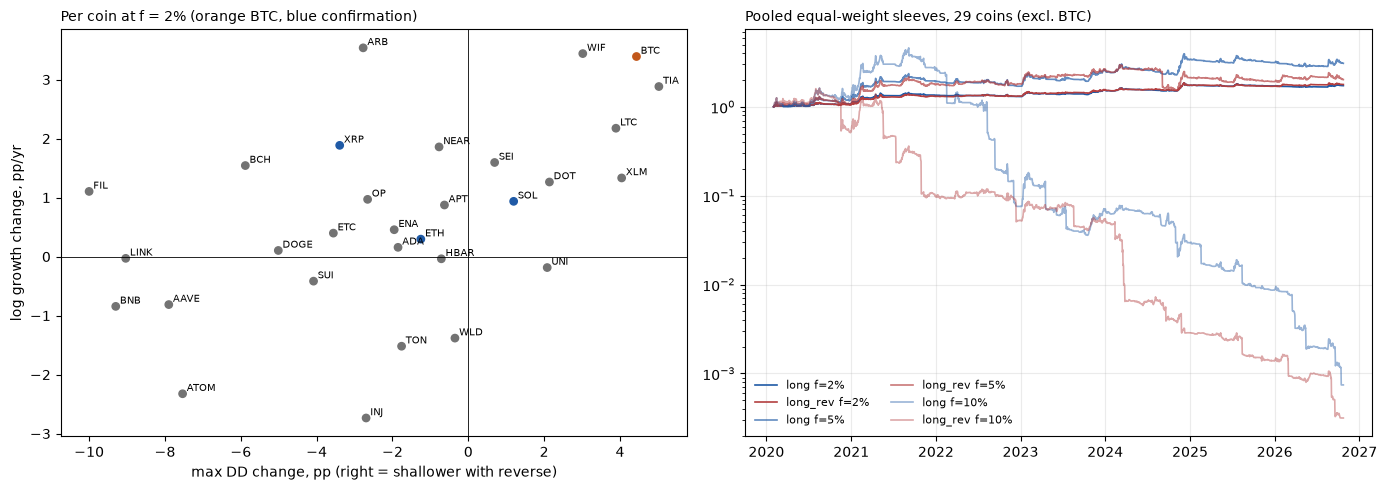

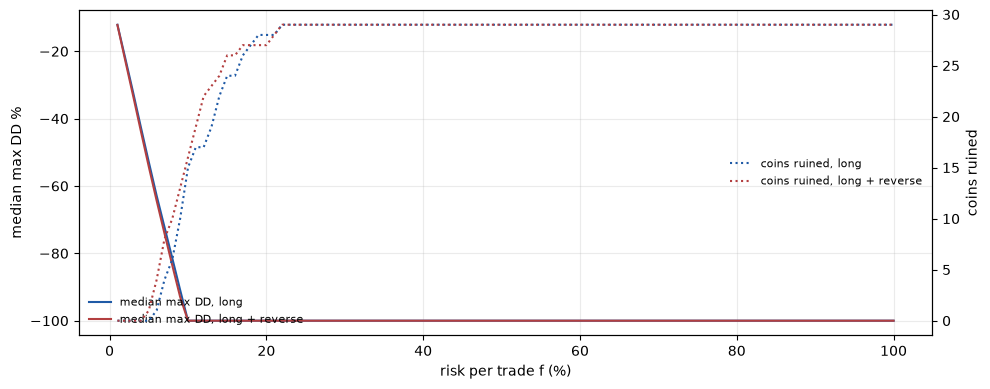

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = PC2.assign(d_dd=(PC2.dd_LR - PC2.dd_L) * 100, d_g=(PC2.g_LR - PC2.g_L) * 100)
col = np.where(x.index == 'BTC', '#c2571a', np.where(x.set == 'confirm', '#1f5aa6', '0.45'))
axes[0].scatter(x.d_dd, x.d_g, c=col, s=28)
for a, r in x.iterrows():
    axes[0].annotate(a, (r.d_dd, r.d_g), fontsize=7, xytext=(3, 2), textcoords='offset points')
axes[0].axhline(0, color='k', lw=0.6); axes[0].axvline(0, color='k', lw=0.6)
axes[0].set_xlabel('max DD change, pp (right = shallower with reverse)'); axes[0].set_ylabel('log growth change, pp/yr')
axes[0].set_title('Per coin at f = 2% (orange BTC, blue confirmation)', loc='left', fontsize=10)
for f_, al in zip(KEEP_F, (1.0, 0.7, 0.45)):
    for v, c in (('long', '#1f5aa6'), ('long_rev', '#b33f40')):
        e = np.exp(ts.pooled_log_returns({a: CURVES[(a, v, f_)] for a in TEST.index}).cumsum())
        axes[1].plot(e.index, e, color=c, alpha=al, lw=1.2, label=f'{v} f={f_:.0%}')
axes[1].set_yscale('log'); axes[1].legend(frameon=False, fontsize=8, ncol=2); axes[1].grid(alpha=0.25)
axes[1].set_title('Pooled equal-weight sleeves, 29 coins (excl. BTC)', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(BYF.f * 100, BYF.median_dd_L * 100, color='#1f5aa6', label='median max DD, long')
ax.plot(BYF.f * 100, BYF.median_dd_LR * 100, color='#b33f40', label='median max DD, long + reverse')
ax2 = ax.twinx(); ax2.plot(BYF.f * 100, BYF.ruined_L, color='#1f5aa6', ls=':', label='coins ruined, long'); ax2.plot(BYF.f * 100, BYF.ruined_LR, color='#b33f40', ls=':', label='coins ruined, long + reverse')
ax.set_xlabel('risk per trade f (%)'); ax.set_ylabel('median max DD %'); ax2.set_ylabel('coins ruined')
ax.legend(loc='lower left', frameon=False, fontsize=8); ax2.legend(loc='center right', frameon=False, fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
TAB.to_csv(OUT / '10_sweeps_all.csv.gz', index=False, compression='gzip')
PC2.to_csv(OUT / '10_per_coin_2pct.csv'); BYF.to_csv(OUT / '10_by_f.csv', index=False); RUIN.to_csv(OUT / '10_ruin.csv', index=False)
COV.to_csv(OUT / '10_coverage.csv', index=False)
pd.DataFrame({f'{a}|{v}|{f_}': c for (a, v, f_), c in CURVES.items()}).to_csv(OUT / '10_curves_P.csv.gz', compression='gzip')
(OUT / '10_decision.json').write_text(json.dumps({'decision': DEC, 'pooled': {str(k): v for k, v in POOL.items()},
    'registration': {'version': ts.VERSION, 'test_set': list(TEST.index), 'f': 0.02, 'sweep': 'P', 'alpha_each': SP.alpha / 3}, 'synthetic': SYNTHETIC}, indent=1, default=str))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '10_manifest.json').write_text(json.dumps({'version': ts.VERSION, 'tb07_version': tr.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'assets': ASSETS, 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\10
VERDICT: NO_IMPROVEMENT
